# Convert and Optimize BoT-SORT multi-object tracking with OpenVINO™

[BoT-SORT](https://github.com/NirAharon/BoT-SORT) ([paper](https://arxiv.org/abs/2206.14651)) tracks people with **two
neural networks** plus a host-side tracker:
* a **YOLOX-X detector** (800×1440, 790 GFLOP per frame) finds the people,
* a **FastReID SBS-S50 ReID network** (ResNeSt-50, 14 GFLOP per crop) embeds each confident detection (2048-d),
* the **BoT-SORT tracker** compensates camera motion, predicts with a Kalman filter and associates detections to tracks
  using IoU fused with appearance similarity.

This tutorial converts and optimizes **both networks** with OpenVINO:
1. Take the tracking config and the **PyTorch FP32 models** exported by [BoT-SORT_PyTorch_Enablement.ipynb](./BoT-SORT_PyTorch_Enablement.ipynb).
2. Convert both to **OpenVINO IR FP32**, then the FP32 IRs to **FP16**.
3. Check accuracy (MOTA / IDF1 on MOT17 val-half) and run both precisions on a video.
4. Quantize FP32 IR → **INT8** with NNCF post-training quantization. If the MOTA drops by more than 2 points, use
   `nncf.quantize_with_accuracy_control`.
5. Run INT8 on the video and measure **average latency and FPS with `benchmark_app`**.
6. Compare every OpenVINO precision with PyTorch FP32 / FP16, and finally run the INT8 pipeline on a second video.

#### Table of contents:

- [Prerequisites](#Prerequisites)
- [Get PyTorch models and tracking config](#Get-PyTorch-models-and-tracking-config)
- [Convert models to OpenVINO IR](#Convert-models-to-OpenVINO-IR)
    - [FP32 IR](#FP32-IR)
    - [FP32 IR to FP16 IR](#FP32-IR-to-FP16-IR)
- [Select inference device](#Select-inference-device)
- [Verify model inference](#Verify-model-inference)
- [Accuracy of OpenVINO FP32 and FP16](#Accuracy-of-OpenVINO-FP32-and-FP16)
- [Run FP32 and FP16 on a video](#Run-FP32-and-FP16-on-a-video)
- [Optimize models using NNCF Post-training Quantization API](#Optimize-models-using-NNCF-Post-training-Quantization-API)
    - [Validate Quantized model inference](#Validate-Quantized-model-inference)
    - [Run INT8 on the video](#Run-INT8-on-the-video)
- [Compare performance of the models with benchmark_app](#Compare-performance-of-the-models-with-benchmark_app)
- [Accuracy and performance: OpenVINO vs PyTorch](#Accuracy-and-performance:-OpenVINO-vs-PyTorch)
- [INT8 tracking on a second video: Luka_Doncic.mp4](#INT8-tracking-on-a-second-video:-Luka_Doncic.mp4)

### Installation Instructions

This is a self-contained example that relies solely on its own code (`botsort_nb_utils.py` next to the notebooks).
We recommend running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

* PyTorch for your device first (Intel GPU: `pip install torch torchvision --index-url https://download.pytorch.org/whl/xpu`),
  then `pip install -r requirements.txt` (OpenVINO, NNCF, motmetrics, ...).
* Data / weights are looked up in the repository and its parent folder (or set the environment variables
  `BOTSORT_DET_WEIGHTS`, `BOTSORT_REID_WEIGHTS`, `MOT17_TRAIN`, `VIDEO_1`, `VIDEO_2`); the Prerequisites cell downloads
  what is missing.

> Run the PyTorch enablement notebook first.

## Prerequisites
[back to top ⬆️](#Table-of-contents:)

In [1]:
# %pip install -q -r requirements.txt
import os, sys, json, time, shutil
from pathlib import Path
import numpy as np, cv2, torch
import openvino as ov
import nncf
from IPython.display import Image, Markdown, display

import botsort_nb_utils as U

core = ov.Core()
print("OpenVINO", ov.__version__, "| NNCF", nncf.__version__)
print("devices:", {d: core.get_property(d, "FULL_DEVICE_NAME") for d in core.available_devices})
OUT = Path("results")
(OUT / "images").mkdir(parents=True, exist_ok=True)

OpenVINO 2026.4.0-22701-36ef3d68c9f | NNCF 3.4.0
devices: {'CPU': 'Intel(R) Core(TM) Ultra X7 358H', 'GPU': 'Intel(R) Arc(TM) B390 GPU (iGPU)', 'NPU': 'Intel(R) AI Boost'}


## Get PyTorch models and tracking config
[back to top ⬆️](#Table-of-contents:)

Both FP32 networks, the configuration and the PyTorch baselines come from the PyTorch enablement notebook (`artifacts/`).

**Is a tracking config needed for OpenVINO?** Yes. Detection / NMS thresholds, the ReID crop pre-processing, the tracker
thresholds and ReID gates, the track buffer with its per-sequence overrides and the camera-motion settings are in
neither weight file nor IR graph. OpenVINO only replaces the networks, so the same config is used. It is embedded into
both IRs' `rt_info` and saved next to them.

In [2]:
ART = Path("artifacts")
assert (ART / "pytorch_results.json").exists(), "run BoT-SORT_PyTorch_Enablement.ipynb first"
cfg = json.load(open(ART / "botsort_config.json"))
pt_results = json.load(open(ART / "pytorch_results.json"))
SETTINGS = pt_results["settings"]
det_pt = U.build_detector(None)
print("detector load_state_dict:", det_pt.load_state_dict(torch.load(ART / "detector_fp32_fused_state_dict.pt", map_location="cpu"), strict=True))
reid_pt = U.build_reid(None)
print("ReID     load_state_dict:", reid_pt.load_state_dict(torch.load(ART / "reid_fp32_state_dict.pt", map_location="cpu"), strict=True))
DET_SHAPE = [1, 3, *cfg["detector"]["input_size_hw"]]
REID_SHAPE = [cfg["reid"]["batch"], 3, *cfg["reid"]["input_hw"]]
print("PyTorch baselines:", {k: (round(v["MOTA"], 2), round(v["IDF1"], 2)) for k, v in pt_results["accuracy"].items()}, "| full evaluation:", SETTINGS["full_evaluation"])

detector load_state_dict: <All keys matched successfully>
ReID     load_state_dict: <All keys matched successfully>
PyTorch baselines: {'PT_FP32': (90.81, 86.84), 'PT_FP16': (90.76, 86.94)} | full evaluation: True


## Convert models to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR). `ov.convert_model`
traces each FP32 module and `ov.save_model` serializes it as an **FP32 IR**. The **FP16 IRs** are made from the
**saved FP32 IRs** with `compress_to_fp16=True`: weights become FP16, inputs/outputs stay f32.

The ReID IR has a **static batch of 8** (the official FastReID batch size). Partial batches are zero-padded, as in the
original implementation.

### FP32 IR
[back to top ⬆️](#Table-of-contents:)

In [3]:
IR_DIR = Path("ov_models")
DET_NAME, REID_NAME = "botsort_yolox_x_detector.xml", "botsort_sbs_s50_reid.xml"
ir = lambda variant, name: IR_DIR / variant / name  # noqa: E731
tracking_config = json.dumps(cfg)


def save_ir(model: ov.Model, xml: Path, compress_to_fp16: bool) -> None:
    model.set_rt_info(tracking_config, ["tracking_config"])  # the tracking config travels with the IR
    xml.parent.mkdir(parents=True, exist_ok=True)
    ov.save_model(model, str(xml), compress_to_fp16=compress_to_fp16)
    json.dump(cfg, open(xml.parent / "botsort_config.json", "w"), indent=2)


for name, module, shape, in_name in ((DET_NAME, det_pt, DET_SHAPE, "images"), (REID_NAME, reid_pt, REID_SHAPE, "crops")):
    if not ir("FP32", name).exists():
        t = time.perf_counter()
        m = ov.convert_model(module, example_input=torch.zeros(shape), input=[ov.PartialShape(shape)])
        m.inputs[0].get_tensor().set_names({in_name})
        save_ir(m, ir("FP32", name), compress_to_fp16=False)
        print(f"{name}: converted in {time.perf_counter() - t:.1f}s")
    print(f"FP32 IR {ir('FP32', name)} ({ir('FP32', name).with_suffix('.bin').stat().st_size / 1e6:.0f} MB)")

FP32 IR ov_models/FP32/botsort_yolox_x_detector.xml (396 MB)
FP32 IR ov_models/FP32/botsort_sbs_s50_reid.xml (102 MB)


### FP32 IR to FP16 IR
[back to top ⬆️](#Table-of-contents:)

In [4]:
for name in (DET_NAME, REID_NAME):
    if not ir("FP16", name).exists():
        save_ir(core.read_model(ir("FP32", name)), ir("FP16", name), compress_to_fp16=True)
    m = core.read_model(ir("FP16", name))
    print(f"FP16 IR {ir('FP16', name)} ({ir('FP16', name).with_suffix('.bin').stat().st_size / 1e6:.0f} MB) | "
          f"input {m.input(0).get_element_type()} {m.input(0).get_partial_shape()} | rt_info tracking_config: {m.has_rt_info(['tracking_config'])}")

FP16 IR ov_models/FP16/botsort_yolox_x_detector.xml (198 MB) | input <Type: 'float32'> [1,3,800,1440] | rt_info tracking_config: True
FP16 IR ov_models/FP16/botsort_sbs_s50_reid.xml (51 MB) | input <Type: 'float32'> [8,3,384,128] | rt_info tracking_config: True


## Select inference device
[back to top ⬆️](#Table-of-contents:)

Select the device from the dropdown list for running inference with OpenVINO.

> **FP32 on GPU:** the GPU plugin executes an FP32 IR in **f16** by default. True FP32, comparable to PyTorch FP32,
> needs `INFERENCE_PRECISION_HINT=f32` (`benchmark_app -infer_precision f32`). All "OV FP32" numbers below use it.

In [5]:
import ipywidgets as widgets

device = widgets.Dropdown(options=core.available_devices + ["AUTO"], value="GPU" if "GPU" in core.available_devices else "CPU", description="Device:")
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='GPU')

## Verify model inference
[back to top ⬆️](#Table-of-contents:)

One MOT17-09 frame through both detector IRs and one batch of its person crops through both ReID IRs, compared with
PyTorch FP32 on CPU: cosine of the raw detector output and of the score map (obj × cls), number of detections, and
cosine of the ReID embeddings.

In [6]:
FP32_PROPS = {"INFERENCE_PRECISION_HINT": "f32"} if device.value.startswith("GPU") else {}
det_ov = {"FP32": U.ov_runner(core, ir("FP32", DET_NAME), device.value, **FP32_PROPS), "FP16": U.ov_runner(core, ir("FP16", DET_NAME), device.value)}
reid_ov = {"FP32": U.ov_runner(core, ir("FP32", REID_NAME), device.value, **FP32_PROPS), "FP16": U.ov_runner(core, ir("FP16", REID_NAME), device.value)}

seq = U.mot17_val_half(["MOT17-09-FRCNN"])[0]
img0 = cv2.imread(str(seq["frames"][0][1]))
x0, r0 = U.preprocess(img0, cfg)
with torch.inference_mode():
    det_ref = det_pt(torch.from_numpy(x0)).numpy()
d_ref = U.postprocess(det_ref, r0, cfg)
crops0, n0 = next(U.batched(U.reid_crops(img0, d_ref[d_ref[:, 4] > 0.6], tuple(cfg["reid"]["input_hw"])), cfg["reid"]["batch"]))
with torch.inference_mode():
    emb_ref = U.normalize_feats(reid_pt(torch.from_numpy(crops0)).numpy()[:n0])
print(f"PyTorch FP32 (CPU): {len(d_ref)} detections")
for p in ("FP32", "FP16"):
    y, ms = U.timeit(det_ov[p], x0, n=10)
    e, ms_r = U.timeit(reid_ov[p], crops0, n=10)
    emb = U.normalize_feats(e[:n0])
    print(f"OV {p} (exec {det_ov[p].exec_precision}): detector {ms:6.1f} ms, cosine raw {U.cosine(y, det_ref):.7f} / scores {U.score_cosine(y, det_ref):.7f}, "
          f"{len(U.postprocess(y, r0, cfg))} detections | ReID {ms_r:5.1f} ms/batch, embedding cosine {np.mean(np.sum(emb * emb_ref, 1)):.6f}")

PyTorch FP32 (CPU): 14 detections


OV FP32 (exec f32): detector  194.3 ms, cosine raw 1.0000000 / scores 1.0000000, 14 detections | ReID  26.5 ms/batch, embedding cosine 1.000000


OV FP16 (exec f16): detector   28.0 ms, cosine raw 0.9999982 / scores 1.0000000, 14 detections | ReID   9.6 ms/batch, embedding cosine 0.999997


## Accuracy of OpenVINO FP32 and FP16
[back to top ⬆️](#Table-of-contents:)

Same MOT17 val-half protocol, host pipeline and tracker configuration as the PyTorch notebook; both networks at the same precision.

In [7]:
ACC_SEQS = SETTINGS["accuracy_sequences"]
acc = dict(pt_results["accuracy"])
for p in ("FP32", "FP16"):
    acc[f"OV_{p}"] = U.mot_eval(det_ov[p], reid_ov[p], cfg, f"OV_{p}", seqs=ACC_SEQS)
ref_acc = acc["PT_FP32"]
rows = ["| Config | MOTA | ΔMOTA vs PT FP32 | IDF1 | ΔIDF1 | IDs | FP | FN |", "|---|---|---|---|---|---|---|---|"]
rows += [f"| {k} | {m['MOTA']:.2f} | {m['MOTA'] - ref_acc['MOTA']:+.2f} | {m['IDF1']:.2f} | {m['IDF1'] - ref_acc['IDF1']:+.2f} | {m['IDs']} | {m['FP']} | {m['FN']} |" for k, m in acc.items()]
display(Markdown("\n".join(rows)))

| Config | MOTA | ΔMOTA vs PT FP32 | IDF1 | ΔIDF1 | IDs | FP | FN |
|---|---|---|---|---|---|---|---|
| PT_FP32 | 90.81 | +0.00 | 86.84 | +0.00 | 158 | 1090 | 3702 |
| PT_FP16 | 90.76 | -0.06 | 86.94 | +0.10 | 160 | 1123 | 3697 |
| OV_FP32 | 90.81 | +0.00 | 86.84 | +0.00 | 158 | 1090 | 3702 |
| OV_FP16 | 90.77 | -0.04 | 86.73 | -0.11 | 161 | 1135 | 3677 |

## Run FP32 and FP16 on a video
[back to top ⬆️](#Table-of-contents:)

The first `VIDEO_SECONDS` (20 s) of `JK_Standing_Next2U.mp4` with the same settings as in the PyTorch notebook; tracks are scored **against the PyTorch FP32 tracks of the same frames** (100 = identical). Set `VIDEO_SECONDS = None` for the whole video.

OV_FP32: 600 frames, 41 unique IDs | detector 194.0 + ReID 28.1 ms/frame | 3.9 FPS end to end | IDF1 vs PT FP32 100.0, MOTA vs PT FP32 100.0


OV_FP16: 600 frames, 41 unique IDs | detector 29.1 + ReID 10.2 ms/frame | 14.0 FPS end to end | IDF1 vs PT FP32 100.0, MOTA vs PT FP32 100.0


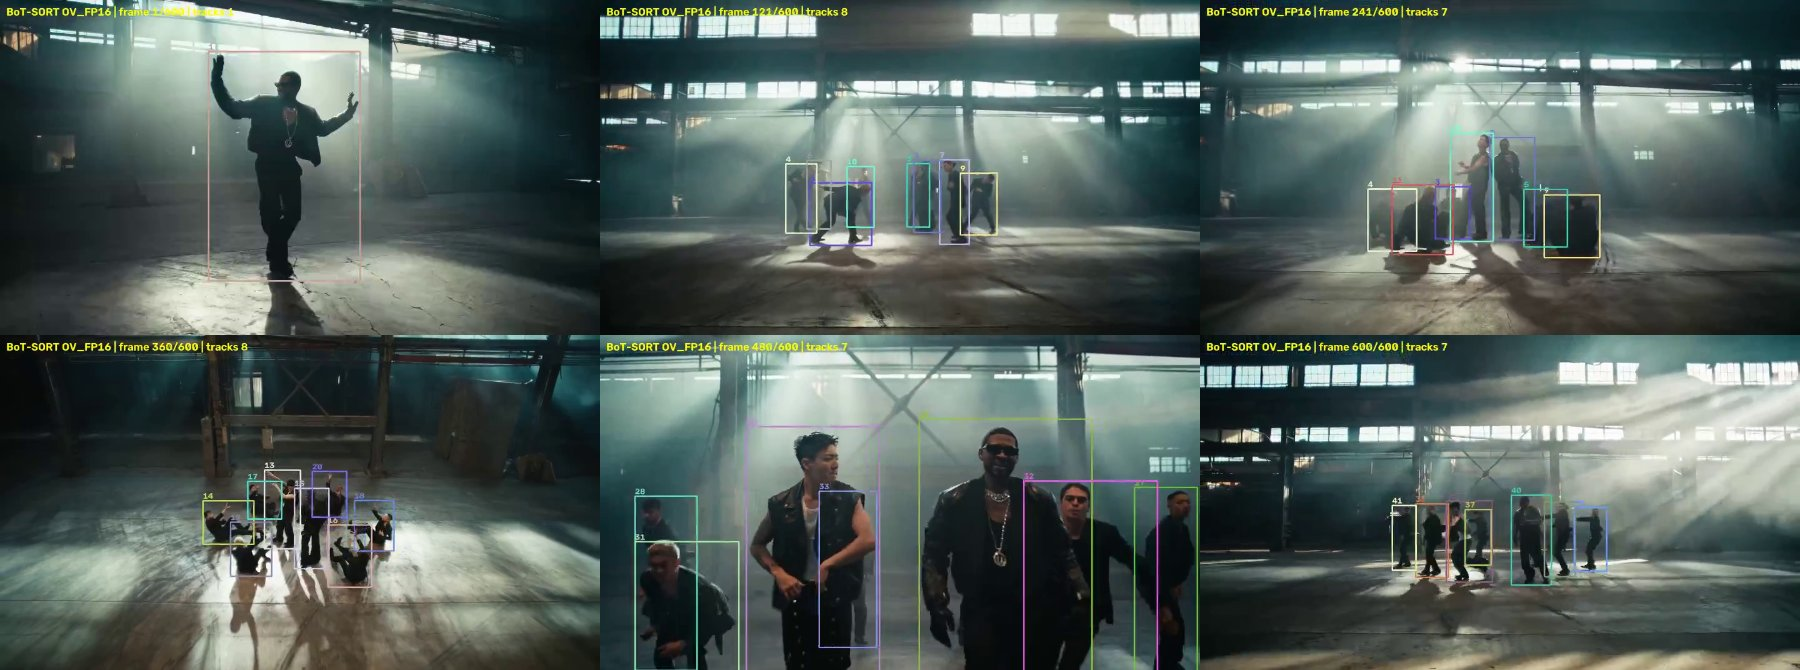

In [8]:
VIDEO_SECONDS = 20  # every video run in this notebook is clipped to the first 20 s; None = whole video
_cap = cv2.VideoCapture(str(U.VIDEO_1))
VIDEO_MAX_FRAMES = int(VIDEO_SECONDS * _cap.get(cv2.CAP_PROP_FPS)) if VIDEO_SECONDS else SETTINGS["video_max_frames"]
_cap.release()
pt_ref_tracks = U.load_video_tracks(pt_results["video_reference_tracks"])
vid = dict(pt_results["video"])


def video_run(tag: str, det_run, reid_run) -> None:
    r = U.track_video(det_run, reid_run, cfg, tag, video=U.VIDEO_1, max_frames=VIDEO_MAX_FRAMES)
    r["stats"].update(U.video_agreement(pt_ref_tracks[: len(r["tracks"])], r["tracks"]))
    vid[tag] = r["stats"]
    s = r["stats"]
    print(f"{tag}: {s['frames']} frames, {s['unique_ids']} unique IDs | detector {s['detector_ms_per_frame']:.1f} + ReID {s['reid_ms_per_frame']:.1f} ms/frame | "
          f"{s['pipeline_fps']:.1f} FPS end to end | IDF1 vs PT FP32 {s['IDF1_vs_ref']:.1f}, MOTA vs PT FP32 {s['MOTA_vs_ref']:.1f}")


for p in ("FP32", "FP16"):
    video_run(f"OV_{p}", det_ov[p], reid_ov[p])
display(Image(U.video_contact_sheet(vid["OV_FP16"]["mp4"], OUT / "images/video_ov_fp16_sheet.jpg"), width=1000))

## Optimize models using NNCF Post-training Quantization API
[back to top ⬆️](#Table-of-contents:)

[NNCF](https://github.com/openvinotoolkit/nncf) provides a suite of advanced algorithms for neural network inference
optimization in OpenVINO with minimal accuracy drop. We use 8-bit quantization in post-training mode (without the
fine-tuning pipeline) for **both networks**. The tracker is not a network and is unchanged.

The optimization process contains the following steps:

1. Create calibration Datasets from MOT17 **train-half** data, which is disjoint from the val-half used for accuracy:
   whole frames for the detector, and batches of 8 ground-truth person crops for the ReID.
2. Run `nncf.quantize` on each **FP32 IR**.
3. Validate: ReID embedding fidelity (cosine vs FP32, rank-1 / mAP), then MOTA / IDF1 of the whole tracker. If MOTA
   drops by **more than 2 points**, run `nncf.quantize_with_accuracy_control` for the detector.
4. Serialize the OpenVINO IRs with `openvino.save_model`.

| Option | Detector | ReID | Why |
|---|---|---|---|
| `preset` | `MIXED` | `MIXED` | symmetric weights, asymmetric activations (SiLU / ReLU outputs are not zero-centred) |
| `ignored_scope` | box-decode tail (grid add, stride mul, `exp`, concat) | `heads.*`: GeM pooling (clamp → x³ → mean → x^⅓) + BN neck | the decode keeps box coordinates exact; quantizing x³ in GeM makes the embeddings drift (cosine vs FP32 0.71 instead of 0.95), and BoT-SORT gates on absolute similarity |
| `subset_size` | 300 frames | 300 batches | calibration samples |
| `fast_bias_correction` | `True` | `True` | full BiasCorrection caches all activations (~27 GB for the detector at 800×1440) |

Please select below whether you would like to run quantization to improve model inference speed.

In [9]:
int8_det_path, int8_reid_path = ir("INT8", DET_NAME), ir("INT8", REID_NAME)
int8_det_ac_path = ir("INT8_accuracy_control", DET_NAME)

to_quantize = widgets.Checkbox(value=True, description="Quantization")
quantization_mode = widgets.Dropdown(
    options=[
        ("Default quantization (accuracy control only if ΔMOTA > 2)", "default"),
        ("Quantization with accuracy control (detector)", "accuracy_control"),
    ],
    value="default",
    description="Mode",
)

widgets.VBox([to_quantize, quantization_mode])

Let's load `skip magic` extension to skip quantization if `to_quantize` is not selected

In [10]:
if not Path("skip_kernel_extension.py").exists():
    try:
        import requests

        r = requests.get(url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/skip_kernel_extension.py", timeout=10)
        r.raise_for_status()
        open("skip_kernel_extension.py", "w").write(r.text)
    except Exception:
        open("skip_kernel_extension.py", "w").write(
            "def skip(line, cell=None):\n    if eval(line):\n        return\n    get_ipython().ex(cell)\n\n\n"
            "def load_ipython_extension(shell):\n    shell.register_magic_function(skip, 'line_cell')\n"
        )

%load_ext skip_kernel_extension

Prepare the calibration datasets: 300 evenly spaced MOT17 train-half frames for the detector (transformed by the
BoT-SORT pre-processing), and 300 batches of 8 ground-truth person crops (pedestrians with visibility ≥ 0.25) from the
same frames for the ReID. Both are wrapped into `nncf.Dataset` objects.

In [11]:
%%skip not $to_quantize.value

N_CALIB = 300
train_half = U.train_half_frames()
image_files = [train_half[i] for i in np.linspace(0, len(train_half) - 1, N_CALIB).round().astype(int)]


def transform_fn(image_path: Path) -> np.ndarray:
    x, _ = U.preprocess(cv2.imread(str(image_path)), cfg)
    return x


reid_calibration_items = list(U.reid_gt_crops(image_files, batch=cfg["reid"]["batch"], size_hw=tuple(cfg["reid"]["input_hw"])))

det_fp32_model = core.read_model(ir("FP32", DET_NAME))
_ops = det_fp32_model.get_ordered_ops()
_t = max(i for i, o in enumerate(_ops) if o.get_type_name() == "Transpose")
det_ignored = [o.get_friendly_name() for o in _ops[_t:] if o.get_type_name() not in ("Constant", "Result")]
reid_ignored = [o.get_friendly_name() for o in core.read_model(ir("FP32", REID_NAME)).get_ordered_ops()
                if o.get_friendly_name().startswith("__module.heads.") and o.get_type_name() not in ("Constant", "Result")]
print(f"{len(image_files)} detector calibration frames, {len(reid_calibration_items)} ReID calibration batches | "
      f"ops kept in float: detector {len(det_ignored)} (box decode), ReID {len(reid_ignored)} ({', '.join(sorted({o.get_type_name() for o in core.read_model(ir('FP32', REID_NAME)).get_ordered_ops() if o.get_friendly_name() in reid_ignored}))})")

300 detector calibration frames, 300 ReID calibration batches | ops kept in float: detector 9 (box decode), ReID 5 (Add, Maximum, Power, ReduceMean)


The `nncf.quantize` function provides an interface for model quantization. It requires an instance of the OpenVINO
Model and a quantization dataset. Optional parameters configure the quantization process: number of samples, preset,
ignored scope, and so on.

For **accuracy control** on the detector, `validation_fn` runs the *whole* BoT-SORT pipeline (candidate detector →
NMS → INT8 ReID → tracker) on a MOT17 val-half subset and returns MOTA. NNCF compiles the candidate models on **CPU**
for this, so the subset is kept short.

>**Note**: Model post-training quantization is a time-consuming process. It takes a few minutes (ReID ~2 min,
>detector ~5 min); accuracy control takes longer.

In [12]:
%%skip not $to_quantize.value

import nncf
import openvino as ov

MAX_DROP = 2.0  # MOTA points (absolute)


def save_int8(model: ov.Model, path: Path, info: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    model.set_rt_info(tracking_config, ["tracking_config"])
    ov.save_model(model, str(path))
    json.dump(cfg, open(path.parent / "botsort_config.json", "w"), indent=2)
    info["fake_quantize_nodes"] = sum(o.get_type_name() == "FakeQuantize" for o in model.get_ordered_ops())
    json.dump(info, open(path.with_suffix(".quantization_info.json"), "w"), indent=2)


def quantize_reid(out_path: Path) -> ov.Model:
    t = time.perf_counter()
    quantized_reid_model = nncf.quantize(
        core.read_model(ir("FP32", REID_NAME)),
        nncf.Dataset(reid_calibration_items),
        preset=nncf.QuantizationPreset.MIXED,
        subset_size=len(reid_calibration_items),
        fast_bias_correction=True,
        ignored_scope=nncf.IgnoredScope(names=reid_ignored, validate=False),
    )
    print(f"Quantized ReID model will be saved to {out_path}")
    save_int8(quantized_reid_model, out_path, {"network": "reid", "preset": "mixed", "ignored_scope": reid_ignored, "time_s": time.perf_counter() - t})
    return quantized_reid_model


def quantize_detector(use_accuracy_control: bool, out_path: Path, reid_run=None) -> ov.Model:
    ov_model = core.read_model(ir("FP32", DET_NAME))  # FP32 IR
    quantization_dataset = nncf.Dataset(image_files, transform_fn)
    calibration_dataset = quantization_dataset
    PRESET = nncf.QuantizationPreset.MIXED
    FAST_BIAS_CORRECTION = True
    IGNORED_SCOPE = nncf.IgnoredScope(names=det_ignored, validate=False)

    # nncf with accuracy control
    if use_accuracy_control:
        DROP_TYPE = nncf.DropType.ABSOLUTE
        CALIB_SIZE = len(image_files)
        validation_items, nncf_validation_fn = U.accuracy_control_validation(reid_run, cfg, seqs=("MOT17-09-FRCNN",), frames=150)
        validation_dataset = nncf.Dataset(validation_items)  # one item = one MOT17 sequence

    t = time.perf_counter()
    if not use_accuracy_control:
        quantized_det_model = nncf.quantize(
            ov_model,
            quantization_dataset,
            preset=PRESET,
            subset_size=len(image_files),
            fast_bias_correction=FAST_BIAS_CORRECTION,
            ignored_scope=IGNORED_SCOPE,
        )
    else:
        quantized_det_model = nncf.quantize_with_accuracy_control(
            ov_model,
            calibration_dataset=calibration_dataset,
            validation_dataset=validation_dataset,
            validation_fn=nncf_validation_fn,
            max_drop=MAX_DROP,
            drop_type=DROP_TYPE,
            preset=PRESET,
            subset_size=CALIB_SIZE,
            fast_bias_correction=FAST_BIAS_CORRECTION,
            ignored_scope=IGNORED_SCOPE,
        )
    print(f"Quantized detector model will be saved to {out_path}")
    save_int8(quantized_det_model, out_path, {"network": "detector", "preset": "mixed", "accuracy_control": use_accuracy_control,
                                              "ignored_scope": det_ignored, "time_s": time.perf_counter() - t})
    return quantized_det_model


if not int8_reid_path.exists():
    quantize_reid(int8_reid_path)
reid_int8_run = U.ov_runner(core, int8_reid_path, device.value)
use_accuracy_control = quantization_mode.value == "accuracy_control"
int8_det_path = int8_det_ac_path if use_accuracy_control else int8_det_path
if not int8_det_path.exists():
    quantize_detector(use_accuracy_control, int8_det_path, reid_int8_run)
for p in (int8_det_path, int8_reid_path):
    print(f"INT8 IR {p} ({p.with_suffix('.bin').stat().st_size / 1e6:.0f} MB) | FakeQuantize nodes: {sum(o.get_type_name() == 'FakeQuantize' for o in core.read_model(p).get_ordered_ops())}")

INFO:nncf:5 ignored nodes were found by names in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 369 __module.heads.pool_layer/aten::clamp/Maximum


INFO:nncf:Not adding activation input quantizer for operation: 377 __module.heads.pool_layer/aten::pow/Power


INFO:nncf:Not adding activation input quantizer for operation: 385 __module.heads.pool_layer/aten::adaptive_avg_pool2d/AdaptiveAvgPool


INFO:nncf:Not adding activation input quantizer for operation: 393 __module.heads.pool_layer/aten::pow/Power_1


...

INFO:nncf:Not adding activation input quantizer for operation: 400 aten::cat/Concat


Output()

Output()

Quantized detector model will be saved to ov_models/INT8/botsort_yolox_x_detector.xml


INT8 IR ov_models/INT8/botsort_yolox_x_detector.xml (100 MB) | FakeQuantize nodes: 180
INT8 IR ov_models/INT8/botsort_sbs_s50_reid.xml (26 MB) | FakeQuantize nodes: 190


### Validate Quantized model inference
[back to top ⬆️](#Table-of-contents:)

First the **ReID embedding fidelity** on MOT17 val-half ground-truth crops: query = crops at frame *f*, gallery = crops
at frame *f* + 15, with rank-1 / mAP and the embedding cosine vs FP32. Then the detector check and MOTA / IDF1 of the
whole INT8 pipeline. If the MOTA drop vs OV FP32 is larger than `MAX_DROP`, the second cell falls back to
`nncf.quantize_with_accuracy_control` for the detector automatically.

1192 crops

| ReID precision | rank-1 (%) | mAP (%) | embedding cosine vs FP32 (mean / min) |
|---|---|---|---|
| OpenVINO FP32 (f32) | 95.54 | 97.21 | - |
| OpenVINO FP16 | 95.35 | 97.08 | 0.99999 / 0.99988 |
| OpenVINO INT8 | 95.54 | 97.17 | 0.95093 / 0.39201 |

OV INT8 detector: 17.1 ms | cosine vs PT FP32: raw 0.99866, scores 0.99977 | 14 detections (PT FP32 14)


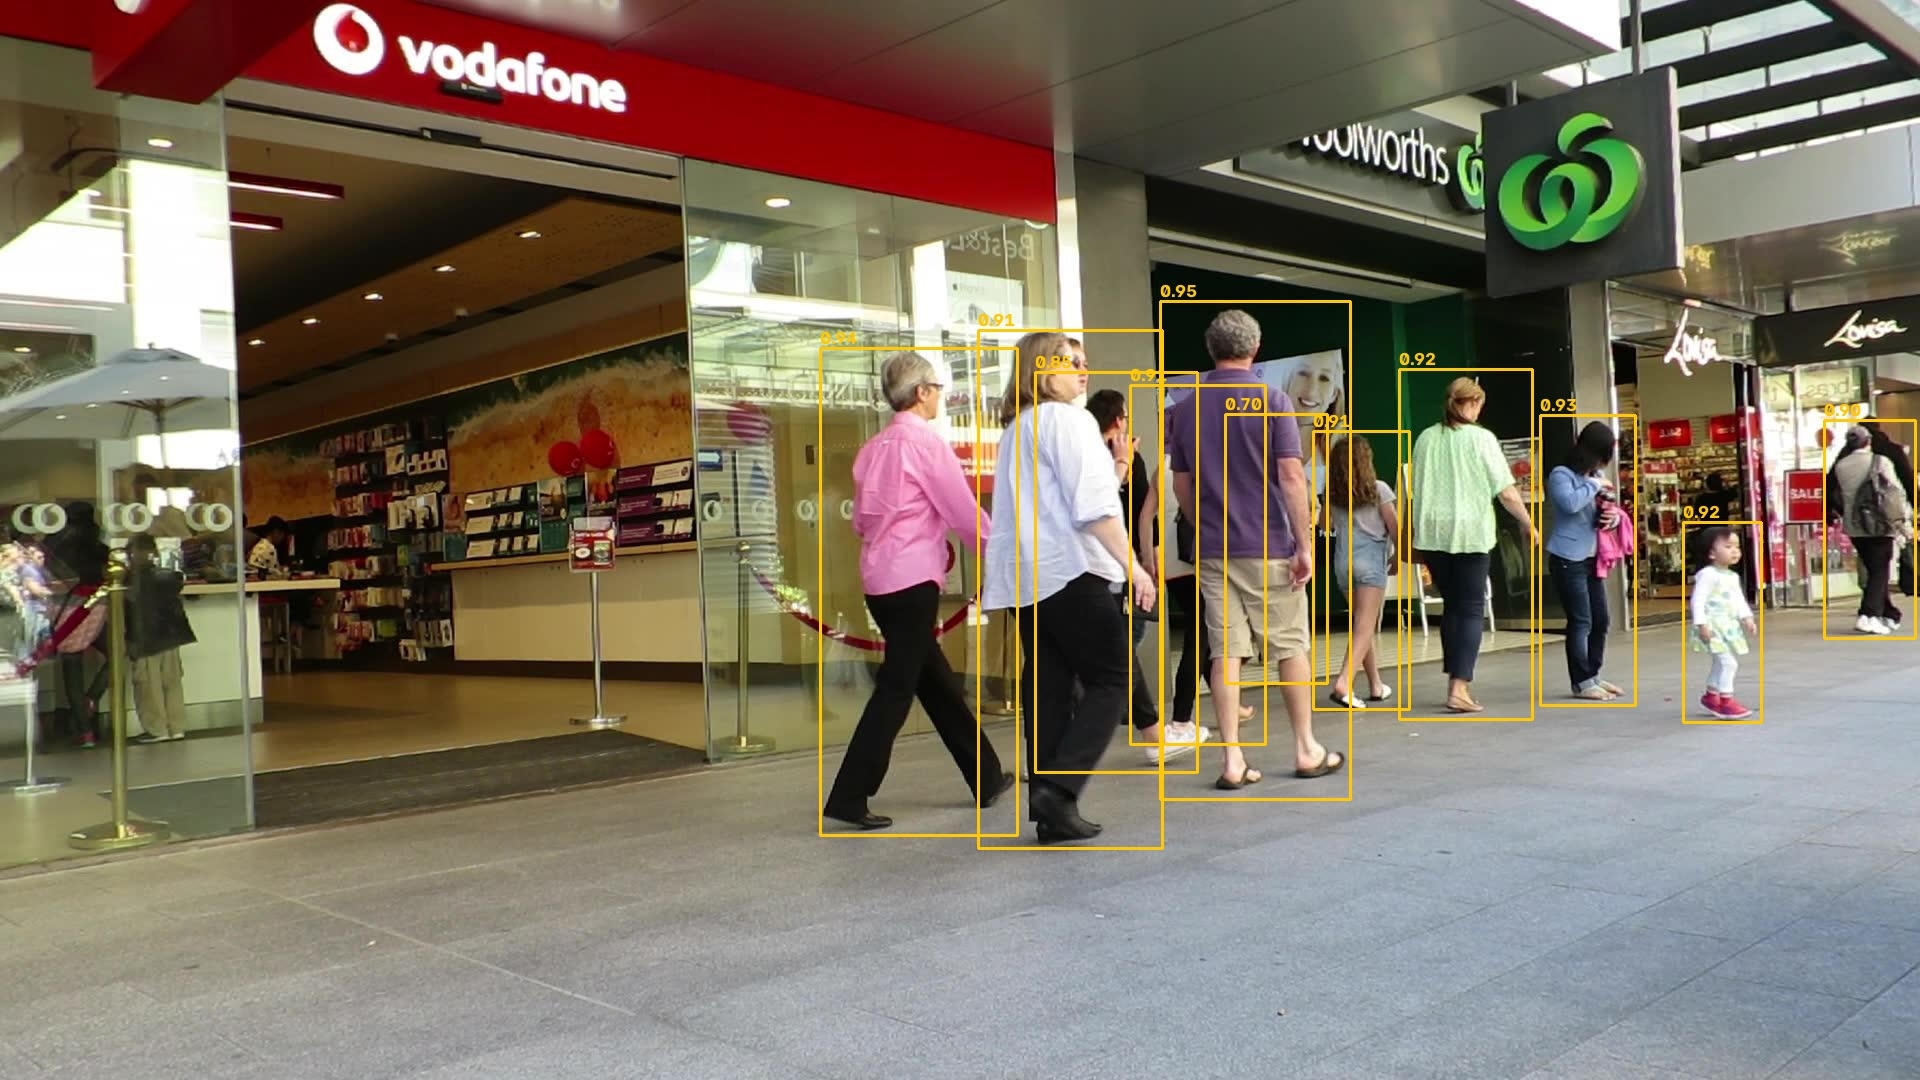

OV_INT8: MOTA 90.71 (drop vs OV FP32 +0.11) | IDF1 87.50 | IDs 180


In [13]:
%%skip not $to_quantize.value

fid = U.reid_fidelity({"OpenVINO FP32 (f32)": reid_ov["FP32"], "OpenVINO FP16": reid_ov["FP16"], "OpenVINO INT8": reid_int8_run},
                      pairs_per_seq=6 if SETTINGS["full_evaluation"] else 2)
rows = ["| ReID precision | rank-1 (%) | mAP (%) | embedding cosine vs FP32 (mean / min) |", "|---|---|---|---|"]
for k, v in fid.items():
    cos = "-" if v["cos_mean"] is None else f"{v['cos_mean']:.5f} / {v['cos_min']:.5f}"
    rows.append(f"| {k} | {v['rank1']:.2f} | {v['mAP']:.2f} | {cos} |")
display(Markdown(f"{next(iter(fid.values()))['crops']} crops\n\n" + "\n".join(rows)))

det_int8_run = U.ov_runner(core, int8_det_path, device.value)
y8, ms8 = U.timeit(det_int8_run, x0, n=10)
d8 = U.postprocess(y8, r0, cfg)
print(f"OV INT8 detector: {ms8:.1f} ms | cosine vs PT FP32: raw {U.cosine(y8, det_ref):.5f}, scores {U.score_cosine(y8, det_ref):.5f} | {len(d8)} detections (PT FP32 {len(d_ref)})")
cv2.imwrite(str(OUT / "images/ov_int8_detections.jpg"), U.draw_dets(img0, d8))
display(Image(str(OUT / "images/ov_int8_detections.jpg"), width=900))
int8_tag = "OV_INT8_AC" if int8_det_path == int8_det_ac_path else "OV_INT8"
acc[int8_tag] = U.mot_eval(det_int8_run, reid_int8_run, cfg, int8_tag, seqs=ACC_SEQS)
drop = acc["OV_FP32"]["MOTA"] - acc[int8_tag]["MOTA"]
print(f"{int8_tag}: MOTA {acc[int8_tag]['MOTA']:.2f} (drop vs OV FP32 {drop:+.2f}) | IDF1 {acc[int8_tag]['IDF1']:.2f} | IDs {acc[int8_tag]['IDs']}")

In [14]:
%%skip not $to_quantize.value

if drop > MAX_DROP and int8_tag == "OV_INT8":
    print(f"MOTA drop {drop:.2f} > {MAX_DROP} -> nncf.quantize_with_accuracy_control (detector)")
    if not int8_det_ac_path.exists():
        quantize_detector(True, int8_det_ac_path, reid_int8_run)
    int8_det_path, int8_tag = int8_det_ac_path, "OV_INT8_AC"
    det_int8_run = U.ov_runner(core, int8_det_path, device.value)
    acc[int8_tag] = U.mot_eval(det_int8_run, reid_int8_run, cfg, int8_tag, seqs=ACC_SEQS)
    print(f"{int8_tag}: MOTA {acc[int8_tag]['MOTA']:.2f} (drop {acc['OV_FP32']['MOTA'] - acc[int8_tag]['MOTA']:+.2f})")
else:
    print(f"MOTA drop {drop:+.2f} <= {MAX_DROP}: plain nncf.quantize() meets the criterion, accuracy control is not needed")

MOTA drop +0.11 <= 2.0: plain nncf.quantize() meets the criterion, accuracy control is not needed


### Run INT8 on the video
[back to top ⬆️](#Table-of-contents:)

OV_INT8: 600 frames, 42 unique IDs | detector 17.9 + ReID 5.3 ms/frame | 18.1 FPS end to end | IDF1 vs PT FP32 97.3, MOTA vs PT FP32 98.7


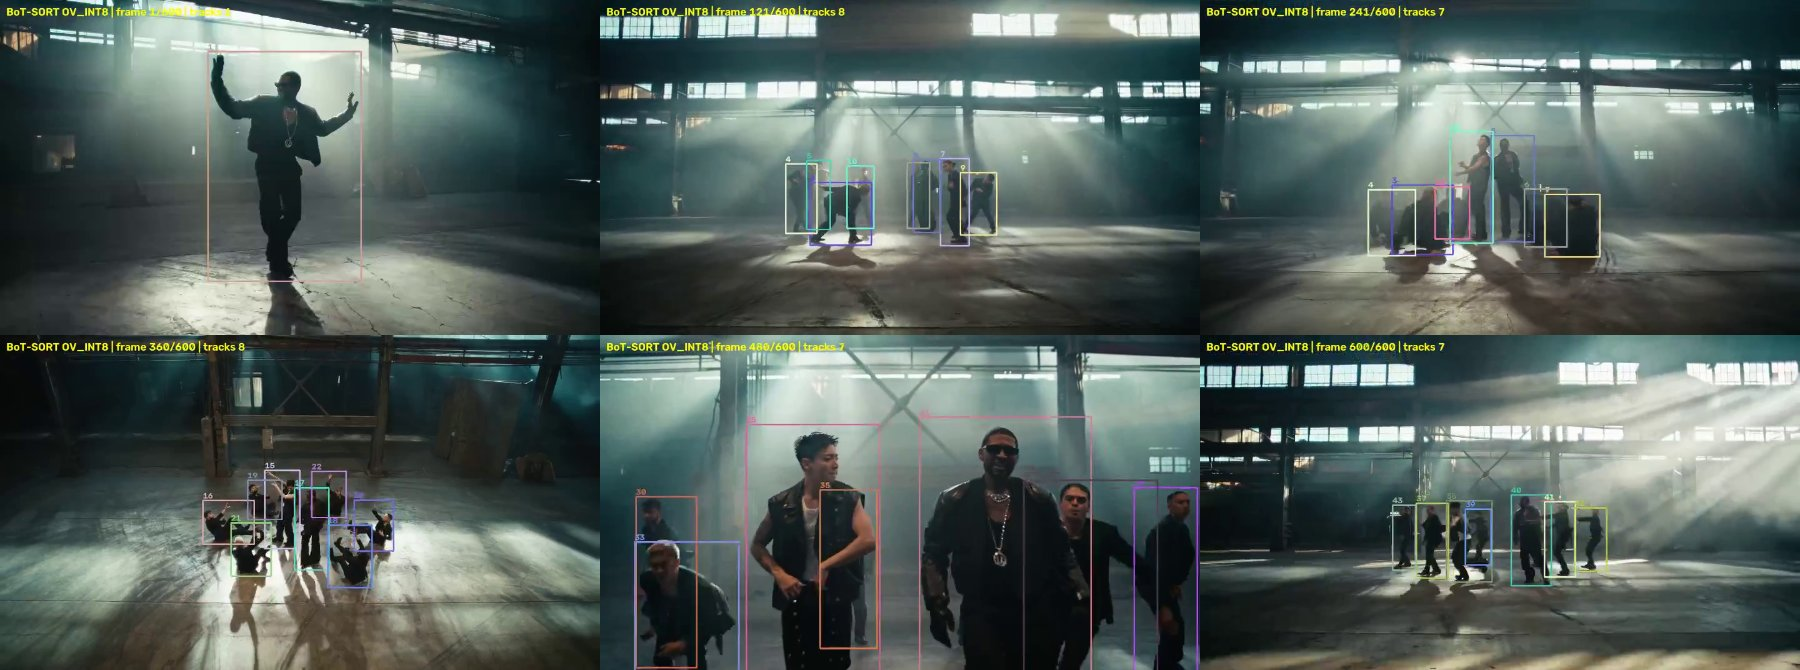

In [15]:
%%skip not $to_quantize.value

video_run(int8_tag, det_int8_run, reid_int8_run)
display(Image(U.video_contact_sheet(vid[int8_tag]["mp4"], OUT / "images/video_ov_int8_sheet.jpg"), width=1000))

## Compare performance of the models with benchmark_app
[back to top ⬆️](#Table-of-contents:)

Finally, use the OpenVINO [Benchmark Tool](https://docs.openvino.ai/2026/learn-openvino/openvino-samples/benchmark-tool.html)
to measure the **average latency** and **throughput** of both networks at FP32 (`-infer_precision f32`), FP16 and
INT8, in the same two modes as the PyTorch notebook:
* `-hint latency -api sync`: 1 request;
* `-hint tput`: async, with the number of requests chosen by the plugin. It is checked below against the PyTorch run.

`-ip f32` feeds f32 input like PyTorch. `-b` must equal the model batch (1 for the detector, 8 for the ReID); without
an explicit batch, `-hint tput` on GPU may enable automatic batching, which PyTorch does not mirror. For the ReID,
FPS = crops per second. As in the PyTorch notebook, every run is preceded by a 10 s cool-down.

> **Note**: For more accurate performance, run `benchmark_app` in a terminal after closing other applications, e.g.
> `benchmark_app -m <model.xml> -d GPU -t 30 -b 1 -shape "[1,3,800,1440]" -hint tput -ip f32`.

In [16]:
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='GPU')

In [17]:
BENCH_TIME = SETTINGS["bench_time_s"]
COOLDOWN_S = SETTINGS.get("cooldown_s", 10)
BENCH = OUT / "benchmark"
BENCH.mkdir(parents=True, exist_ok=True)
FP32_FLAGS = "-infer_precision f32" if device.value.startswith("GPU") else ""
# benchmark_app ships with the openvino pip package; use the one next to this kernel's python if it is not on PATH
benchmark_app = shutil.which("benchmark_app") or str(Path(sys.executable).parent / "benchmark_app")
NETS = {"detector": (DET_NAME, 1, "[" + ",".join(map(str, DET_SHAPE)) + "]"), "reid": (REID_NAME, cfg["reid"]["batch"], "[" + ",".join(map(str, REID_SHAPE)) + "]")}

In [18]:
# Inference FP32 models (OpenVINO IR, executed in f32)
for net, (name, b, shape) in NETS.items():
    xml = ir("FP32", name)
    time.sleep(COOLDOWN_S)
    !$benchmark_app -m $xml -d $device.value -b $b -hint latency -api sync -ip f32 {FP32_FLAGS} -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_OV_FP32_sync.log 2>&1
    time.sleep(COOLDOWN_S)
    !$benchmark_app -m $xml -d $device.value -b $b -hint tput -ip f32 {FP32_FLAGS} -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_OV_FP32_tput.log 2>&1
    for mode in ("sync", "tput"):
        r = U.parse_benchmark_log(open(BENCH / f"{net}_OV_FP32_{mode}.log").read())
        print(f"{net:8s} OV FP32 {mode}: Average {r['avg_ms']:.2f} ms | Throughput {r['fps']:.1f} FPS | {r['api']} nireq={r['nireq']}")

detector OV FP32 sync: Average 192.60 ms | Throughput 5.2 FPS | sync nireq=1


detector OV FP32 tput: Average 740.50 ms | Throughput 5.3 FPS | async nireq=4


reid     OV FP32 sync: Average 22.60 ms | Throughput 353.8 FPS | sync nireq=1
reid     OV FP32 tput: Average 90.47 ms | Throughput 352.5 FPS | async nireq=4


In [19]:
# Inference FP16 models (OpenVINO IR)
for net, (name, b, shape) in NETS.items():
    xml = ir("FP16", name)
    time.sleep(COOLDOWN_S)
    !$benchmark_app -m $xml -d $device.value -b $b -hint latency -api sync -ip f32  -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_OV_FP16_sync.log 2>&1
    time.sleep(COOLDOWN_S)
    !$benchmark_app -m $xml -d $device.value -b $b -hint tput -ip f32  -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_OV_FP16_tput.log 2>&1
    for mode in ("sync", "tput"):
        r = U.parse_benchmark_log(open(BENCH / f"{net}_OV_FP16_{mode}.log").read())
        print(f"{net:8s} OV FP16 {mode}: Average {r['avg_ms']:.2f} ms | Throughput {r['fps']:.1f} FPS | {r['api']} nireq={r['nireq']}")

detector OV FP16 sync: Average 27.06 ms | Throughput 36.9 FPS | sync nireq=1
detector OV FP16 tput: Average 109.13 ms | Throughput 36.5 FPS | async nireq=4


reid     OV FP16 sync: Average 8.01 ms | Throughput 997.2 FPS | sync nireq=1
reid     OV FP16 tput: Average 32.17 ms | Throughput 991.0 FPS | async nireq=4


In [20]:
if int8_det_path.exists() and int8_reid_path.exists():
    # Inference INT8 models (OpenVINO IR)
    for net, xml in (("detector", int8_det_path), ("reid", int8_reid_path)):
        b, shape = NETS[net][1], NETS[net][2]
        time.sleep(COOLDOWN_S)
        !$benchmark_app -m $xml -d $device.value -b $b -hint latency -api sync -ip f32 -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_{int8_tag}_sync.log 2>&1
        time.sleep(COOLDOWN_S)
        !$benchmark_app -m $xml -d $device.value -b $b -hint tput -ip f32 -shape "$shape" -t $BENCH_TIME > {BENCH}/{net}_{int8_tag}_tput.log 2>&1
        for mode in ("sync", "tput"):
            r = U.parse_benchmark_log(open(BENCH / f"{net}_{int8_tag}_{mode}.log").read())
            print(f"{net:8s} {int8_tag} {mode}: Average {r['avg_ms']:.2f} ms | Throughput {r['fps']:.1f} FPS | {r['api']} nireq={r['nireq']}")

detector OV_INT8 sync: Average 15.61 ms | Throughput 63.9 FPS | sync nireq=1
detector OV_INT8 tput: Average 62.58 ms | Throughput 63.7 FPS | async nireq=4


reid     OV_INT8 sync: Average 3.41 ms | Throughput 2334.0 FPS | sync nireq=1
reid     OV_INT8 tput: Average 13.73 ms | Throughput 2305.7 FPS | async nireq=4


## Accuracy and performance: OpenVINO vs PyTorch
[back to top ⬆️](#Table-of-contents:)

All numbers come from the same machine with the same settings. Accuracy is MOT17 val-half (identical host pipeline and
tracker config). Performance is `benchmark_app` for OpenVINO and the benchmark_app-equivalent PyTorch benchmark, with
the same api / nireq / shape / f32 I/O; **average** latency is reported. The **network time per MOT17 frame** =
detector latency + (ReID batches per frame, measured during the accuracy run) × ReID batch latency.

In [21]:
perf = {}
for k, r in pt_results["benchmark"].items():
    net, _, p, mode = k.split("_")
    perf[(net, f"PT_{p}", mode)] = {"avg_ms": r["avg_ms"], "fps": r["fps"], "nireq": r["nireq"]}
ov_tags = ["OV_FP32", "OV_FP16"] + ([int8_tag] if "int8_tag" in globals() else [])
for tag in ov_tags:
    for net in NETS:
        for mode in ("sync", "tput"):
            f = BENCH / f"{net}_{tag}_{mode}.log"
            if f.exists():
                r = U.parse_benchmark_log(f.read_text())
                perf[(net, tag, mode)] = {"avg_ms": r["avg_ms"], "fps": r["fps"], "nireq": r["nireq"]}
nireq_ov = perf.get(("detector", "OV_FP16", "tput"), {}).get("nireq")
print(f"benchmark_app -hint tput used nireq={nireq_ov}; PyTorch tput used nireq={SETTINGS['tput_nireq']}"
      + ("  -> apples-to-apples" if nireq_ov == SETTINGS["tput_nireq"] else "  -> MISMATCH: re-run the PyTorch tput benchmark with this nireq"))

names = {"PT_FP32": "PyTorch FP32", "PT_FP16": "PyTorch FP16 (official)", "OV_FP32": "OpenVINO FP32 (f32)", "OV_FP16": "OpenVINO FP16",
         "OV_INT8": "OpenVINO INT8 (NNCF)", "OV_INT8_AC": "OpenVINO INT8 (NNCF, accuracy control)"}
table = []
for c in [k for k in names if k in acc]:
    ds, rsync, dt = perf.get(("detector", c, "sync")), perf.get(("reid", c, "sync")), perf.get(("detector", c, "tput"))
    rs = acc[c]["reid_batches_per_frame"]
    frame_ms = ds["avg_ms"] + rs * rsync["avg_ms"] if ds and rsync else None
    table.append({"config": names[c], "MOTA": round(acc[c]["MOTA"], 2), "dMOTA_vs_PT_FP32": round(acc[c]["MOTA"] - acc["PT_FP32"]["MOTA"], 2),
                  "IDF1": round(acc[c]["IDF1"], 2), "IDs": acc[c]["IDs"], "detector_sync_avg_ms": ds and ds["avg_ms"], "detector_tput_fps": dt and dt["fps"],
                  "reid_sync_avg_ms_per_batch": perf.get(("reid", c, "sync"), {}).get("avg_ms"), "reid_tput_crops_per_s": perf.get(("reid", c, "tput"), {}).get("fps"),
                  "reid_batches_per_frame": round(rs, 2), "network_ms_per_frame": frame_ms and round(frame_ms, 1), "network_fps": frame_ms and round(1000 / frame_ms, 1),
                  "video_IDF1_vs_PT_FP32": vid.get(c, {}).get("IDF1_vs_ref")})
base = table[0]["network_ms_per_frame"]
fm = lambda v, p=1: "-" if v is None else (f"{v:.{p}f}" if isinstance(v, float) else str(v))  # noqa: E731
rows = ["| Config (detector + ReID) | MOTA | ΔMOTA | IDF1 | IDs | detector AVG ms | detector tput FPS | ReID AVG ms / batch | ReID tput crops/s | network ms / frame (FPS) | speed-up vs PT FP32 | video IDF1 vs PT FP32 |",
        "|---|---|---|---|---|---|---|---|---|---|---|---|"]
for r in table:
    rows.append(f"| {r['config']} | {r['MOTA']:.2f} | {r['dMOTA_vs_PT_FP32']:+.2f} | {r['IDF1']:.2f} | {r['IDs']} | {fm(r['detector_sync_avg_ms'])} | {fm(r['detector_tput_fps'])} | "
                f"{fm(r['reid_sync_avg_ms_per_batch'], 2)} | {fm(r['reid_tput_crops_per_s'], 0)} | {fm(r['network_ms_per_frame'])} ({fm(r['network_fps'])}) | "
                f"{fm(base / r['network_ms_per_frame'] if r['network_ms_per_frame'] else None, 2)}x | {fm(r['video_IDF1_vs_PT_FP32'])} |")
display(Markdown("\n".join(rows)))
json.dump({"table": table, "accuracy": acc, "video": vid, "benchmark": {"|".join(k): v for k, v in perf.items()}}, open(OUT / "ov_vs_pytorch_results.json", "w"), indent=2, default=str)
import csv

with open(OUT / "ov_vs_pytorch_results.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(table[0].keys()))
    w.writeheader()
    w.writerows(table)
print("saved", OUT / "ov_vs_pytorch_results.json", "and .csv")

benchmark_app -hint tput used nireq=4; PyTorch tput used nireq=4  -> apples-to-apples


| Config (detector + ReID) | MOTA | ΔMOTA | IDF1 | IDs | detector AVG ms | detector tput FPS | ReID AVG ms / batch | ReID tput crops/s | network ms / frame (FPS) | speed-up vs PT FP32 | video IDF1 vs PT FP32 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| PyTorch FP32 | 90.81 | +0.00 | 86.84 | 158 | 189.1 | 4.9 | 40.34 | 199 | 302.0 (3.3) | 1.00x | 100.0 |
| PyTorch FP16 (official) | 90.76 | -0.06 | 86.94 | 160 | 52.8 | 18.4 | 14.37 | 554 | 93.0 (10.8) | 3.25x | 100.0 |
| OpenVINO FP32 (f32) | 90.81 | +0.00 | 86.84 | 158 | 192.6 | 5.3 | 22.60 | 352 | 255.9 (3.9) | 1.18x | 100.0 |
| OpenVINO FP16 | 90.77 | -0.04 | 86.73 | 161 | 27.1 | 36.5 | 8.01 | 991 | 49.5 (20.2) | 6.10x | 100.0 |
| OpenVINO INT8 (NNCF) | 90.71 | -0.11 | 87.50 | 180 | 15.6 | 63.7 | 3.41 | 2306 | 25.2 (39.6) | 11.98x | 97.3 |

saved results/ov_vs_pytorch_results.json and .csv


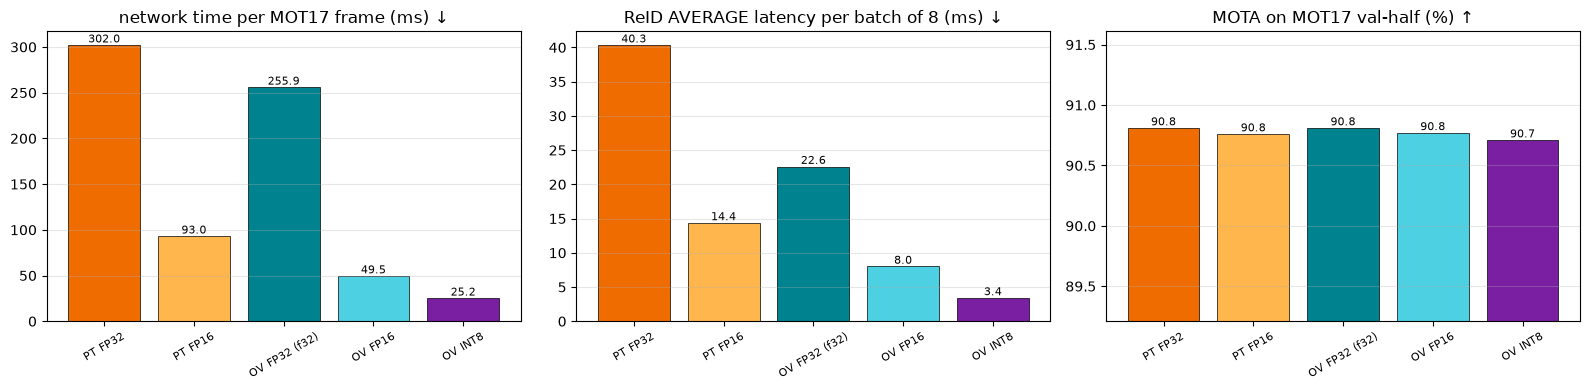

In [22]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
lbl = [r["config"].replace("OpenVINO", "OV").replace("PyTorch", "PT").replace(" (NNCF, accuracy control)", " AC").replace(" (NNCF)", "").replace(" (official)", "") for r in table]
col = ["#ef6c00", "#ffb74d", "#00838f", "#4dd0e1", "#7b1fa2", "#ab47bc"][: len(table)]
for ax, key, title in ((axs[0], "network_ms_per_frame", "network time per MOT17 frame (ms) ↓"), (axs[1], "reid_sync_avg_ms_per_batch", "ReID AVERAGE latency per batch of 8 (ms) ↓"),
                       (axs[2], "MOTA", "MOTA on MOT17 val-half (%) ↑")):
    vals = [r[key] or 0 for r in table]
    b = ax.bar(lbl, vals, color=col, edgecolor="k", lw=0.5)
    ax.bar_label(b, fmt="%.1f", fontsize=8)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    if key == "MOTA":
        ax.set_ylim(min(vals) - 1.5, max(vals) + 0.8)
plt.tight_layout()
plt.savefig(OUT / "images/ov_vs_pytorch.png", dpi=130)
plt.show()

## INT8 tracking on a second video: Luka_Doncic.mp4
[back to top ⬆️](#Table-of-contents:)

A final end-to-end check of the **INT8** pipeline (INT8 detector + INT8 ReID + BoT-SORT with ORB camera-motion
compensation) on unseen footage: the first `VIDEO_SECONDS` (20 s) of a basketball highlight clip (1280×720, 60 fps, ~160 s, ~9.6k frames) with fast
motion, players crossing each other, camera pans, replays and hard cuts.

* The tracker frame rate follows the video (60 fps), so the 30-frame track buffer becomes 60 frames (1 s).
* The detector was trained on MOT17 pedestrians, so it detects **every person**: spectators and bench players too,
  not only the ten players. Expect many tracks in arena shots, and many ReID crops per frame. This is the worst case for
  BoT-SORT's cost.
* Outputs: an annotated half-resolution MP4 in `results/video/`, a contact sheet, an **ID timeline** (one row per track
  ID, red dashed = detected shot cuts; long rows within a shot = stable IDs), and an embedded preview clip.
  Set `VIDEO_SECONDS = None` (in the video section above) to track the whole clip.

In [23]:
assert U.VIDEO_2.exists(), f"{U.rel(U.VIDEO_2)} not found - put Luka_Doncic.mp4 into the repository (or set VIDEO_2=/path/to/video.mp4)"
cap = cv2.VideoCapture(str(U.VIDEO_2))
VIDEO_2_MAX_FRAMES = int(VIDEO_SECONDS * cap.get(5)) if VIDEO_SECONDS else None
print(f"{U.VIDEO_2.name}: {int(cap.get(3))}x{int(cap.get(4))} @ {cap.get(5):.2f} fps, {int(cap.get(7))} frames ({cap.get(7) / cap.get(5):.0f} s)"
      f" -> tracking {VIDEO_2_MAX_FRAMES or int(cap.get(7))} frames")
cap.release()

if "det_int8_run" in globals():
    final_tag, final_det, final_reid = int8_tag, det_int8_run, reid_int8_run
else:  # quantization skipped
    final_tag, final_det, final_reid = "OV_FP16", det_ov["FP16"], reid_ov["FP16"]
v2 = U.track_video(final_det, final_reid, cfg, f"{final_tag}_Luka_Doncic", video=U.VIDEO_2, max_frames=VIDEO_2_MAX_FRAMES)
s = v2["stats"]
print(f"{final_tag}: {s['frames']} frames | {s['shots']} shots | {s['unique_ids']} unique IDs | {s['mean_tracks_per_frame']:.1f} tracks/frame | "
      f"detector {s['detector_ms_per_frame']:.1f} ms + ReID {s['reid_ms_per_frame']:.1f} ms ({s['reid_batches_per_frame']:.1f} batches) per frame | "
      f"{s['pipeline_fps']:.1f} FPS end to end (incl. decode, ORB GMC, tracker, drawing, encoding) | GMC fall-backs {s['gmc_failures']} | video -> {s['mp4']}")

Luka_Doncic.mp4: 1280x720 @ 59.94 fps, 9595 frames (160 s) -> tracking 1198 frames


OV_INT8: 1198 frames | 14 shots | 439 unique IDs | 24.2 tracks/frame | detector 17.9 ms + ReID 14.2 ms (3.1 batches) per frame | 15.3 FPS end to end (incl. decode, ORB GMC, tracker, drawing, encoding) | GMC fall-backs 3 | video -> results/video/OV_INT8_Luka_Doncic_tracked.mp4


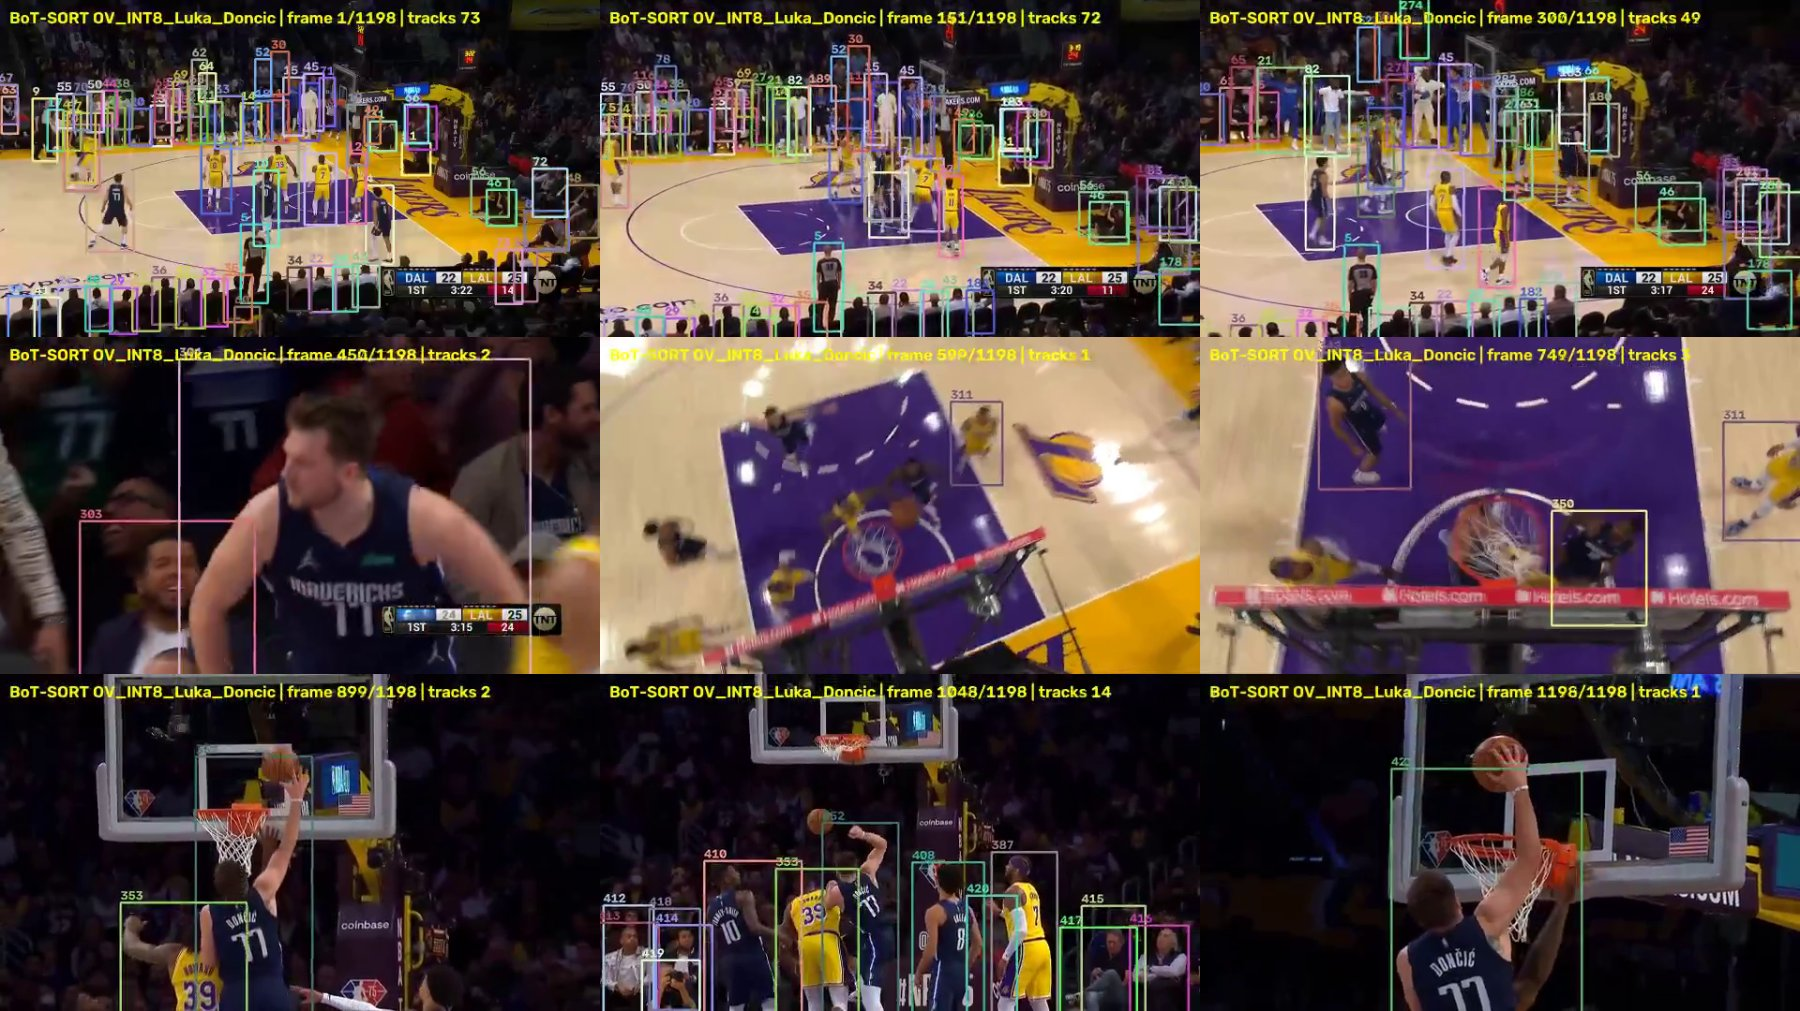

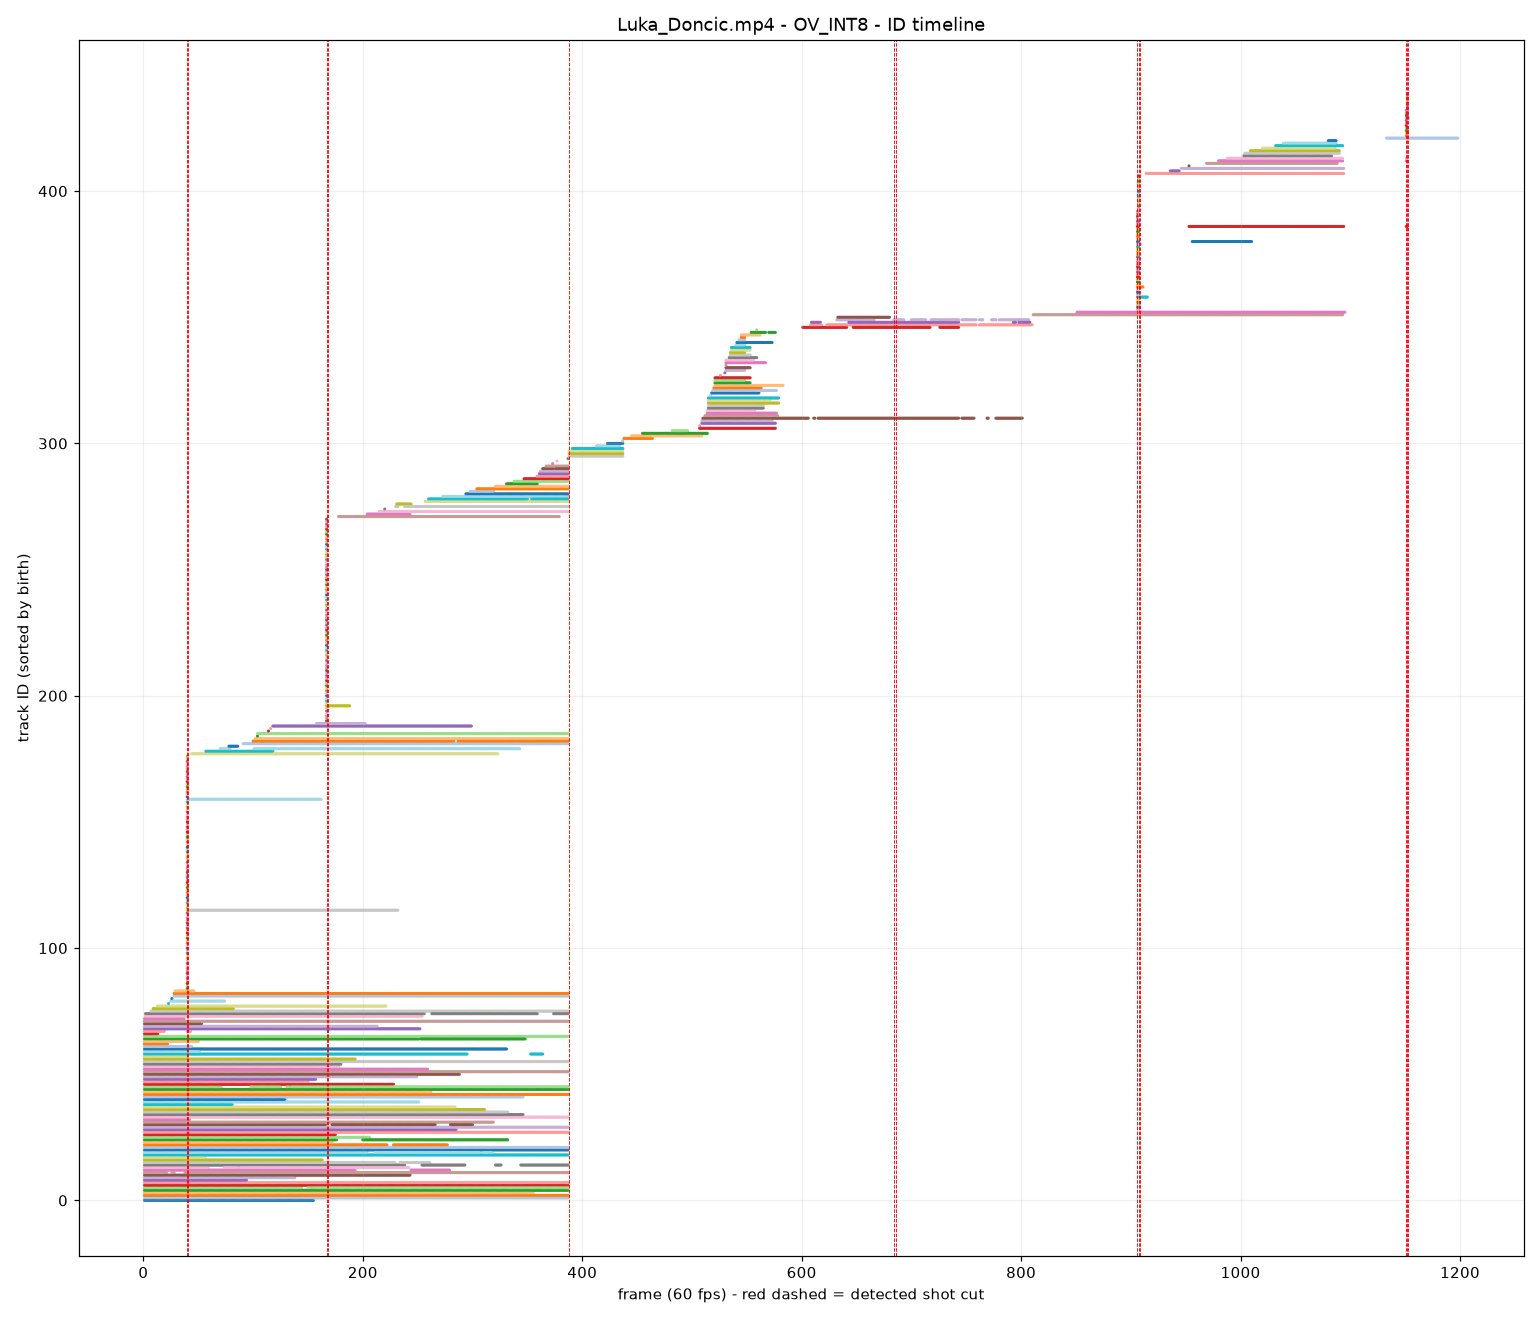

439 IDs: 117 live >= 1 s (median 3.8 s, max 6.5 s) - the players and steady spectators; 262 live < 10 frames - mostly flickering detections of partly visible spectators, which a MOT17 pedestrian detector also finds | shot cuts detected: 13


In [24]:
display(Image(U.video_contact_sheet(v2["stats"]["mp4"], OUT / f"images/video2_{final_tag.lower()}_sheet.jpg", n=9, cols=3), width=1000))
display(Image(U.plot_id_timeline(v2["tracks"], v2["cuts"], OUT / f"images/video2_{final_tag.lower()}_id_timeline.png",
                                 f"{U.VIDEO_2.name} - {final_tag} - ID timeline", fps=v2["stats"]["fps"]), width=1000))
life = {}
for t in v2["tracks"]:
    for tid in t:
        life[tid] = life.get(tid, 0) + 1
lens = np.array(sorted(life.values()))
fps2 = v2["stats"]["fps"]
long_ = lens[lens >= fps2]
print(f"{len(lens)} IDs: {(lens >= fps2).sum()} live >= 1 s (median {np.median(long_) / fps2:.1f} s, max {lens.max() / fps2:.1f} s) - the players and steady spectators; "
      f"{(lens < 10).sum()} live < 10 frames - mostly flickering detections of partly visible spectators, which a MOT17 pedestrian detector also finds | "
      f"shot cuts detected: {len(v2['cuts'])}")

In [25]:
from IPython.display import Video

preview = U.video_preview(v2["stats"]["mp4"], OUT / f"video/{final_tag}_Luka_Doncic_preview.mp4", start_s=0, duration_s=12, width=480)
Video(preview, embed=True, width=720)

## Next steps
[back to top ⬆️](#Table-of-contents:)

* Deeper OpenVINO GPU profiling of both networks (per-layer `-pc`, exec graph, roofline) and the NNCF variant study:
  see the project `SUMMARY.md` and `report/PROFILING_AND_ROOFLINE_README.md`.
* Production pipeline: run the detector and the ReID asynchronously (`AsyncInferQueue`, nireq 2–4) and overlap them
  with the CPU work of the previous frame (ORB camera-motion compensation, crops, Kalman, matching). In crowded scenes,
  run ReID only for tracks that IoU alone cannot resolve.

In [26]:
# Clean up the files created by this notebook (uncomment to run)
# shutil.rmtree("ov_models", ignore_errors=True)
# shutil.rmtree("results", ignore_errors=True)